# Model Deployment Basics & Neural Networks from Scratch


In [1]:
import os, time, pickle, warnings
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.datasets import load_breast_cancer, make_moons, load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")
np.random.seed(42)
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
print("NumPy", np.__version__)

NumPy 2.1.3


---
# Part 1 - Model Deployment Basics: Saving and Loading Models



In [2]:
# Train a model: scaling + logistic regression in a single Pipeline
data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.2, random_state=42, stratify=data.target
)

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000)),
])
pipe.fit(X_train, y_train)
print("Test accuracy (original model):", round(pipe.score(X_test, y_test), 4))

Test accuracy (original model): 0.9825


### 1.1 Saving and loading with `pickle`

In [4]:
os.makedirs("models", exist_ok=True)

with open("models/breast_cancer_pipe.pkl", "wb") as f:
    pickle.dump(pipe, f)

with open("models/breast_cancer_pipe.pkl", "rb") as f:
    pickle_model = pickle.load(f)

print("Loaded model accuracy:", round(pickle_model.score(X_test, y_test), 4))
print("Predictions identical:", np.array_equal(pipe.predict(X_test), pickle_model.predict(X_test)))

Loaded model accuracy: 0.9825
Predictions identical: True


### 1.2 Saving and loading with `joblib`

In [5]:
joblib.dump(pipe, "models/breast_cancer_pipe.joblib")
joblib_model = joblib.load("models/breast_cancer_pipe.joblib")

print("Loaded model accuracy:", round(joblib_model.score(X_test, y_test), 4))
print("Predictions identical:", np.array_equal(pipe.predict(X_test), joblib_model.predict(X_test)))

Loaded model accuracy: 0.9825
Predictions identical: True


### 1.3 `pickle` vs `joblib` on a larger model



In [6]:
rf = RandomForestClassifier(n_estimators=300, random_state=42).fit(X_train, y_train)

def timed(fn, *a, **k):
    t = time.perf_counter(); fn(*a, **k); return time.perf_counter() - t

def save_pickle():
    with open("models/rf.pkl", "wb") as f: pickle.dump(rf, f)

t_pkl = timed(save_pickle)
t_jl = timed(joblib.dump, rf, "models/rf.joblib")
t_jlc = timed(joblib.dump, rf, "models/rf_compressed.joblib", compress=3)

size = lambda p: os.path.getsize(p) / 1024
print(f"pickle            : {t_pkl:.3f}s  {size('models/rf.pkl'):8.1f} KB")
print(f"joblib            : {t_jl:.3f}s  {size('models/rf.joblib'):8.1f} KB")
print(f"joblib compress=3 : {t_jlc:.3f}s  {size('models/rf_compressed.joblib'):8.1f} KB")

pickle            : 0.017s     924.9 KB
joblib            : 0.184s     948.3 KB
joblib compress=3 : 0.147s     186.1 KB


### 1.4 Save metadata with the model



In [7]:
artifact = {
    "model": pipe,
    "feature_names": list(data.feature_names),
    "target_names": list(data.target_names),
    "sklearn_version": __import__("sklearn").__version__,
    "test_accuracy": float(pipe.score(X_test, y_test)),
    "version": "1.0.0",
}
joblib.dump(artifact, "models/breast_cancer_v1.joblib")

loaded = joblib.load("models/breast_cancer_v1.joblib")

def predict_one(sample, artifact=loaded):
    sample = np.asarray(sample).reshape(1, -1)
    if sample.shape[1] != len(artifact["feature_names"]):
        raise ValueError("Wrong number of features")
    idx = artifact["model"].predict(sample)[0]
    proba = artifact["model"].predict_proba(sample)[0].max()
    return artifact["target_names"][idx], round(float(proba), 4)

print(predict_one(X_test[0]), "| true label:", data.target_names[y_test[0]])

(np.str_('malignant'), 1.0) | true label: malignant


---
# Part 2 - Perceptrons, Activation Functions, Forward & Backward Propagation

## 2.1 The perceptron



In [8]:
class Perceptron:
    def __init__(self, n_inputs, lr=0.1, epochs=20):
        self.w = np.zeros(n_inputs)
        self.b = 0.0
        self.lr, self.epochs = lr, epochs

    def predict(self, X):
        return (X @ self.w + self.b >= 0).astype(int)

    def fit(self, X, y):
        for _ in range(self.epochs):
            errors = 0
            for xi, yi in zip(X, y):
                update = self.lr * (yi - self.predict(xi.reshape(1, -1))[0])
                self.w += update * xi
                self.b += update
                errors += int(update != 0)
            if errors == 0:
                break
        return self

X_logic = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
gates = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}

for name, y in gates.items():
    p = Perceptron(2, lr=0.1, epochs=50).fit(X_logic, np.array(y))
    pred = p.predict(X_logic)
    print(f"{name:3s}  predictions={pred}  targets={y}  accuracy={np.mean(pred == y):.2f}")

AND  predictions=[0 0 0 1]  targets=[0, 0, 0, 1]  accuracy=1.00
OR   predictions=[0 1 1 1]  targets=[0, 1, 1, 1]  accuracy=1.00
XOR  predictions=[1 1 0 0]  targets=[0, 1, 1, 0]  accuracy=0.50


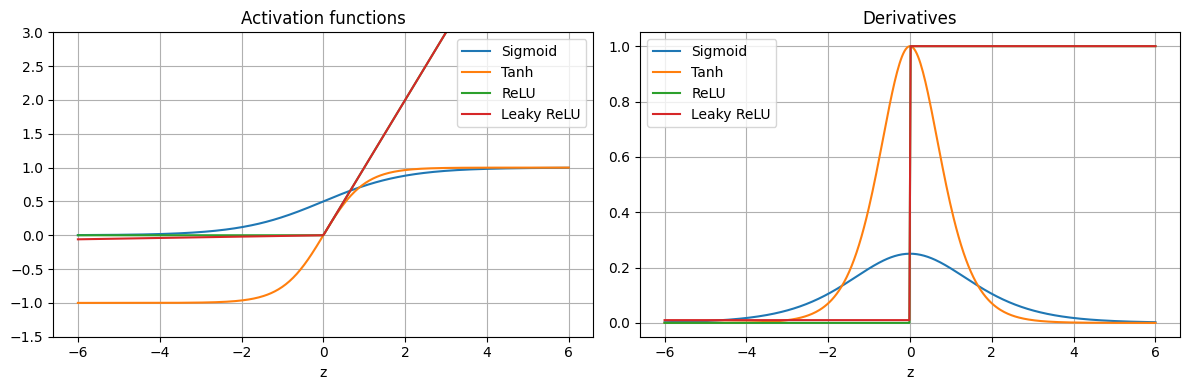

softmax([2.0, 1.0, 0.1]) = [[0.659 0.242 0.099]]


In [9]:
def sigmoid(z):      return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
def sigmoid_d(z):    s = sigmoid(z); return s * (1 - s)
def tanh(z):         return np.tanh(z)
def tanh_d(z):       return 1 - np.tanh(z) ** 2
def relu(z):         return np.maximum(0, z)
def relu_d(z):       return (z > 0).astype(float)
def leaky_relu(z, a=0.01):   return np.where(z > 0, z, a * z)
def leaky_relu_d(z, a=0.01): return np.where(z > 0, 1.0, a)
def linear(z):       return z
def linear_d(z):     return np.ones_like(z)

def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)      # numerical stability
    e = np.exp(z)
    return e / np.sum(e, axis=1, keepdims=True)

zs = np.linspace(-6, 6, 400)
acts = {"Sigmoid": (sigmoid, sigmoid_d), "Tanh": (tanh, tanh_d),
        "ReLU": (relu, relu_d), "Leaky ReLU": (leaky_relu, leaky_relu_d)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, (f, d) in acts.items():
    axes[0].plot(zs, f(zs), label=name)
    axes[1].plot(zs, d(zs), label=name)
axes[0].set_title("Activation functions"); axes[1].set_title("Derivatives")
for ax in axes: ax.legend(); ax.set_xlabel("z")
axes[0].set_ylim(-1.5, 3); plt.tight_layout(); plt.show()

print("softmax([2.0, 1.0, 0.1]) =", np.round(softmax(np.array([[2.0, 1.0, 0.1]])), 3))



## 2.3 Forward and backward propagation by hand



In [10]:
x  = np.array([[0.5, 0.8]])
y  = np.array([[1.0]])
W1 = np.array([[0.1, 0.4], [0.2, -0.3]]);  b1 = np.array([[0.0, 0.1]])
W2 = np.array([[0.3], [-0.2]]);            b2 = np.array([[0.05]])

Z1 = x @ W1 + b1;  A1 = sigmoid(Z1)
Z2 = A1 @ W2 + b2; A2 = sigmoid(Z2)
loss = -(y * np.log(A2) + (1 - y) * np.log(1 - A2)).item()
print("Z1 =", Z1.round(4), " A1 =", A1.round(4))
print("Z2 =", Z2.round(4), " A2 (prediction) =", A2.round(4))
print("BCE loss =", round(loss, 4))

dZ2 = A2 - y
dW2 = A1.T @ dZ2;  db2 = dZ2.sum(axis=0, keepdims=True)
dA1 = dZ2 @ W2.T
dZ1 = dA1 * sigmoid_d(Z1)
dW1 = x.T @ dZ1;   db1 = dZ1.sum(axis=0, keepdims=True)
print("\ndW2 =", dW2.ravel().round(5), " db2 =", db2.ravel().round(5))
print("dW1 =\n", dW1.round(5), "\ndb1 =", db1.ravel().round(5))

lr = 0.5
W2n, b2n = W2 - lr * dW2, b2 - lr * db2
W1n, b1n = W1 - lr * dW1, b1 - lr * db1
A2_new = sigmoid(sigmoid(x @ W1n + b1n) @ W2n + b2n)
print(f"\nPrediction before update: {A2.item():.4f}  ->  after one step: {A2_new.item():.4f} (target 1)")

Z1 = [[0.21 0.06]]  A1 = [[0.5523 0.515 ]]
Z2 = [[0.1127]]  A2 (prediction) = [[0.5281]]
BCE loss = 0.6384

dW2 = [-0.26061 -0.243  ]  db2 = [-0.47186]
dW1 =
 [[-0.0175   0.01179]
 [-0.028    0.01886]] 
db1 = [-0.035    0.02357]

Prediction before update: 0.5281  ->  after one step: 0.6194 (target 1)


In [11]:
def loss_fn(W1_, b1_, W2_, b2_):
    a2 = sigmoid(sigmoid(x @ W1_ + b1_) @ W2_ + b2_)
    return -(y * np.log(a2) + (1 - y) * np.log(1 - a2)).item()

eps = 1e-6
num_dW1 = np.zeros_like(W1)
for i in range(W1.shape[0]):
    for j in range(W1.shape[1]):
        Wp, Wm = W1.copy(), W1.copy()
        Wp[i, j] += eps; Wm[i, j] -= eps
        num_dW1[i, j] = (loss_fn(Wp, b1, W2, b2) - loss_fn(Wm, b1, W2, b2)) / (2 * eps)

print("Analytic dW1:\n", dW1.round(7))
print("Numerical dW1:\n", num_dW1.round(7))
print("Max abs difference:", np.abs(dW1 - num_dW1).max())

Analytic dW1:
 [[-0.017501   0.0117858]
 [-0.0280015  0.0188573]]
Numerical dW1:
 [[-0.017501   0.0117858]
 [-0.0280015  0.0188573]]
Max abs difference: 2.6258818036639653e-11


---
# Part 3 - Loss Functions and Optimizers

## 3.1 Loss functions


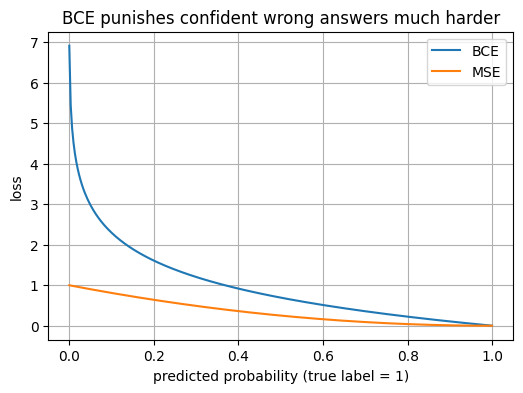

Categorical cross-entropy: 0.367
MSE: 0.1667  MAE: 0.3333


In [12]:
EPS = 1e-12

def mse(y, p):  return np.mean((y - p) ** 2)
def mae(y, p):  return np.mean(np.abs(y - p))

def bce(y, p):
    p = np.clip(p, EPS, 1 - EPS)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

def cce(Y, P):
    P = np.clip(P, EPS, 1.0)
    return -np.mean(np.sum(Y * np.log(P), axis=1))

# Compare MSE vs BCE when the true label is 1
p = np.linspace(0.001, 0.999, 300)
plt.plot(p, [bce(np.array([1.0]), np.array([v])) for v in p], label="BCE")
plt.plot(p, [mse(np.array([1.0]), np.array([v])) for v in p], label="MSE")
plt.xlabel("predicted probability (true label = 1)"); plt.ylabel("loss")
plt.title("BCE punishes confident wrong answers much harder"); plt.legend(); plt.show()

y_true = np.array([[0, 1, 0], [1, 0, 0]])
y_pred = np.array([[0.1, 0.8, 0.1], [0.6, 0.3, 0.1]])
print("Categorical cross-entropy:", round(cce(y_true, y_pred), 4))
print("MSE:", round(mse(np.array([3., 5., 2.]), np.array([2.5, 5.5, 2.]))
, 4), " MAE:", round(mae(np.array([3., 5., 2.]), np.array([2.5, 5.5, 2.])), 4))

## 3.2 Optimizers



In [13]:
class SGD:
    def __init__(self, lr=0.01, momentum=0.0):
        self.lr, self.momentum = lr, momentum
        self.v = {}

    def step(self, params, grads):
        for k in params:
            if self.momentum > 0:
                self.v[k] = self.momentum * self.v.get(k, 0) + grads[k]
                params[k] -= self.lr * self.v[k]
            else:
                params[k] -= self.lr * grads[k]


class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr, self.b1, self.b2, self.eps = lr, beta1, beta2, eps
        self.m, self.v, self.t = {}, {}, 0

    def step(self, params, grads):
        self.t += 1
        for k in params:
            g = grads[k]
            self.m[k] = self.b1 * self.m.get(k, 0) + (1 - self.b1) * g
            self.v[k] = self.b2 * self.v.get(k, 0) + (1 - self.b2) * g ** 2
            m_hat = self.m[k] / (1 - self.b1 ** self.t)
            v_hat = self.v[k] / (1 - self.b2 ** self.t)
            params[k] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

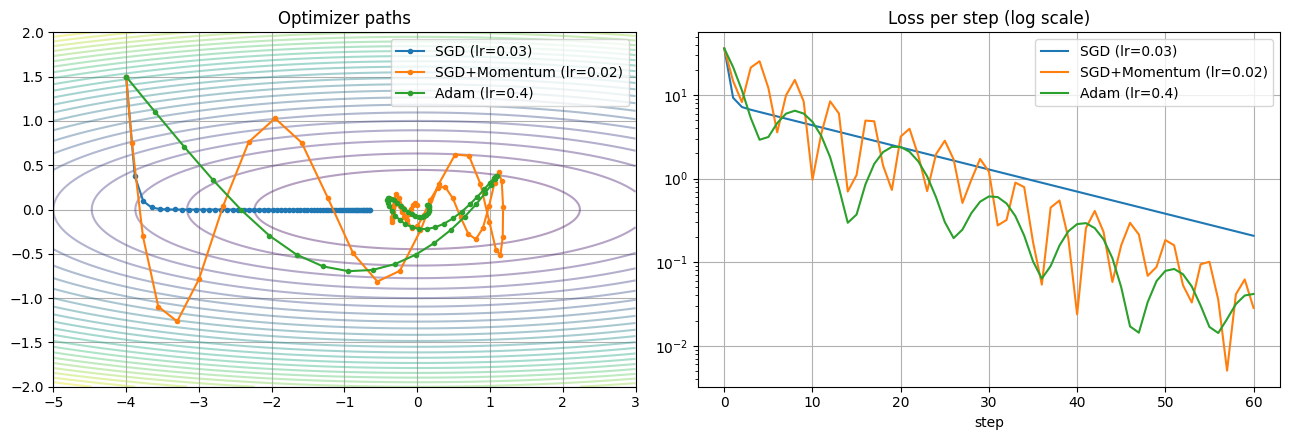

In [14]:
def f(p):      return 0.5 * p["xy"][0] ** 2 + 12.5 * p["xy"][1] ** 2
def grad(p):   return {"xy": np.array([p["xy"][0], 25.0 * p["xy"][1]])}

def run(opt, steps=60, start=(-4.0, 1.5)):
    p = {"xy": np.array(start, dtype=float)}
    path, losses = [p["xy"].copy()], [f(p)]
    for _ in range(steps):
        opt.step(p, grad(p))
        path.append(p["xy"].copy()); losses.append(f(p))
    return np.array(path), losses

runs = {
    "SGD (lr=0.03)":            run(SGD(lr=0.03)),
    "SGD+Momentum (lr=0.02)":   run(SGD(lr=0.02, momentum=0.9)),
    "Adam (lr=0.4)":            run(Adam(lr=0.4)),
}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
gx, gy = np.meshgrid(np.linspace(-5, 3, 200), np.linspace(-2, 2, 200))
ax[0].contour(gx, gy, 0.5 * gx**2 + 12.5 * gy**2, levels=25, alpha=0.4)
for name, (path, losses) in runs.items():
    ax[0].plot(path[:, 0], path[:, 1], marker=".", label=name)
    ax[1].plot(losses, label=name)
ax[0].set_title("Optimizer paths"); ax[0].legend()
ax[1].set_yscale("log"); ax[1].set_title("Loss per step (log scale)")
ax[1].set_xlabel("step"); ax[1].legend()
plt.tight_layout(); plt.show()

---
# Part 4 - Neural Network from Scratch (NumPy)



In [15]:
ACT = {
    "relu":       (relu, relu_d),
    "tanh":       (tanh, tanh_d),
    "sigmoid":    (sigmoid, sigmoid_d),
    "leaky_relu": (leaky_relu, leaky_relu_d),
    "linear":     (linear, linear_d),
    "softmax":    (softmax, None),
}

class NeuralNetwork:
    def __init__(self, layer_sizes, hidden_activation="relu",
                 output_activation="sigmoid", loss="bce", seed=42):
        valid = {("sigmoid", "bce"), ("softmax", "cce"), ("linear", "mse")}
        assert (output_activation, loss) in valid, f"Use one of {valid}"
        self.sizes = list(layer_sizes)
        self.hact, self.oact, self.loss_name = hidden_activation, output_activation, loss
        self.L = len(self.sizes) - 1                 # number of weight layers

        rng = np.random.default_rng(seed)
        self.params = {}
        for i in range(1, self.L + 1):
            fan_in = self.sizes[i - 1]
            scale = np.sqrt(2.0 / fan_in) if hidden_activation in ("relu", "leaky_relu") else np.sqrt(1.0 / fan_in)
            self.params[f"W{i}"] = rng.standard_normal((fan_in, self.sizes[i])) * scale
            self.params[f"b{i}"] = np.zeros((1, self.sizes[i]))
        self.history = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}

    # ---------------- forward ----------------
    def forward(self, X):
        self.cache = {"A0": X}
        A = X
        for i in range(1, self.L + 1):
            Z = A @ self.params[f"W{i}"] + self.params[f"b{i}"]
            act = self.oact if i == self.L else self.hact
            A = ACT[act][0](Z)
            self.cache[f"Z{i}"], self.cache[f"A{i}"] = Z, A
        return A

    # ---------------- loss ----------------
    def compute_loss(self, Y_hat, Y):
        return {"bce": bce, "cce": cce, "mse": mse}[self.loss_name](Y, Y_hat)

    # ---------------- backward ----------------
    def backward(self, Y):
        m = Y.shape[0]
        grads = {}
        A_out = self.cache[f"A{self.L}"]

        if self.loss_name in ("bce", "cce"):
            dZ = (A_out - Y) / m                       # sigmoid+BCE and softmax+CCE simplify to this
        else:                                          # linear output + MSE
            dZ = 2.0 * (A_out - Y) / (m * Y.shape[1])

        for i in range(self.L, 0, -1):
            grads[f"W{i}"] = self.cache[f"A{i-1}"].T @ dZ
            grads[f"b{i}"] = dZ.sum(axis=0, keepdims=True)
            if i > 1:
                dA = dZ @ self.params[f"W{i}"].T
                dZ = dA * ACT[self.hact][1](self.cache[f"Z{i-1}"])
        return grads

    # ---------------- inference ----------------
    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X):
        out = self.forward(X)
        if self.oact == "softmax":
            return np.argmax(out, axis=1)
        if self.oact == "sigmoid":
            return (out >= 0.5).astype(int).ravel()
        return out

    def _accuracy(self, X, Y):
        if self.oact == "softmax":
            return np.mean(self.predict(X) == np.argmax(Y, axis=1))
        if self.oact == "sigmoid":
            return np.mean(self.predict(X) == Y.ravel())
        return np.nan

    # ---------------- training ----------------
    def fit(self, X, Y, epochs=100, batch_size=32, optimizer=None,
            validation_data=None, verbose=10, seed=0):
        optimizer = optimizer or Adam(lr=0.001)
        rng = np.random.default_rng(seed)
        n = X.shape[0]
        for epoch in range(1, epochs + 1):
            idx = rng.permutation(n)
            for start in range(0, n, batch_size):
                b = idx[start:start + batch_size]
                self.forward(X[b])
                grads = self.backward(Y[b])
                optimizer.step(self.params, grads)

            # epoch-level metrics
            self.history["loss"].append(self.compute_loss(self.forward(X), Y))
            self.history["acc"].append(self._accuracy(X, Y))
            if validation_data is not None:
                Xv, Yv = validation_data
                self.history["val_loss"].append(self.compute_loss(self.forward(Xv), Yv))
                self.history["val_acc"].append(self._accuracy(Xv, Yv))
            if verbose and (epoch % verbose == 0 or epoch == 1):
                msg = f"epoch {epoch:4d}  loss={self.history['loss'][-1]:.4f}  acc={self.history['acc'][-1]:.4f}"
                if validation_data is not None:
                    msg += f"  val_loss={self.history['val_loss'][-1]:.4f}  val_acc={self.history['val_acc'][-1]:.4f}"
                print(msg)
        return self

    # ---------------- persistence ----------------
    def save(self, path):
        joblib.dump({"sizes": self.sizes, "hact": self.hact, "oact": self.oact,
                     "loss": self.loss_name, "params": self.params}, path)

    @classmethod
    def load(cls, path):
        d = joblib.load(path)
        net = cls(d["sizes"], d["hact"], d["oact"], d["loss"])
        net.params = d["params"]
        return net

def plot_history(net, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(net.history["loss"], label="train")
    if net.history["val_loss"]: ax[0].plot(net.history["val_loss"], label="validation")
    ax[0].set_title(f"Loss {title}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(net.history["acc"], label="train")
    if net.history["val_acc"]: ax[1].plot(net.history["val_acc"], label="validation")
    ax[1].set_title(f"Accuracy {title}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

In [16]:
def gradient_check(net, X, Y, eps=1e-6):
    net.forward(X)
    analytic = net.backward(Y)
    worst = 0.0
    for k, P in net.params.items():
        num = np.zeros_like(P)
        it = np.nditer(P, flags=["multi_index"])
        for _ in it:
            ix = it.multi_index
            old = P[ix]
            P[ix] = old + eps; lp = net.compute_loss(net.forward(X), Y)
            P[ix] = old - eps; lm = net.compute_loss(net.forward(X), Y)
            P[ix] = old
            num[ix] = (lp - lm) / (2 * eps)
        rel = np.linalg.norm(analytic[k] - num) / (np.linalg.norm(analytic[k]) + np.linalg.norm(num) + 1e-12)
        worst = max(worst, rel)
    return worst

rng = np.random.default_rng(1)
Xc = rng.standard_normal((6, 3))
checks = [
    ("tanh   + sigmoid/BCE", dict(hidden_activation="tanh", output_activation="sigmoid", loss="bce"), (rng.random((6, 1)) > .5).astype(float), 1),
    ("relu   + softmax/CCE", dict(hidden_activation="relu", output_activation="softmax", loss="cce"), np.eye(4)[rng.integers(0, 4, 6)], 4),
    ("sigmoid+ linear/MSE",  dict(hidden_activation="sigmoid", output_activation="linear", loss="mse"), rng.standard_normal((6, 2)), 2),
]
for name, kw, Yc, out in checks:
    net = NeuralNetwork([3, 5, 4, out], **kw)
    err = gradient_check(net, Xc, Yc)
    print(f"{name:22s} relative error = {err:.2e}  {'PASS' if err < 1e-6 else 'CHECK!'}")

tanh   + sigmoid/BCE   relative error = 1.56e-09  PASS
relu   + softmax/CCE   relative error = 1.87e-09  PASS
sigmoid+ linear/MSE    relative error = 1.34e-08  PASS



## 4.2 Solving XOR (what a single perceptron could not do)

In [17]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([[0], [1], [1], [0]], dtype=float)

xor_net = NeuralNetwork([2, 4, 1], hidden_activation="tanh", output_activation="sigmoid", loss="bce", seed=3)
xor_net.fit(X_xor, y_xor, epochs=2000, batch_size=4, optimizer=Adam(lr=0.02), verbose=500)

print("\nPredicted probabilities:", xor_net.predict_proba(X_xor).ravel().round(3))
print("Predicted classes      :", xor_net.predict(X_xor), " targets:", y_xor.ravel().astype(int))

epoch    1  loss=0.8846  acc=0.2500
epoch  500  loss=0.0081  acc=1.0000
epoch 1000  loss=0.0027  acc=1.0000
epoch 1500  loss=0.0013  acc=1.0000
epoch 2000  loss=0.0008  acc=1.0000

Predicted probabilities: [0.    0.999 0.999 0.001]
Predicted classes      : [0 1 1 0]  targets: [0 1 1 0]


## 4.3 Non-linear classification: two moons

We also compare **SGD** and **Adam** on the same architecture and data.

SGD (lr=0.1)             final train loss=0.0659  test accuracy=0.9880
SGD+Momentum (lr=0.05)   final train loss=0.0676  test accuracy=0.9880
Adam (lr=0.01)           final train loss=0.0674  test accuracy=0.9880


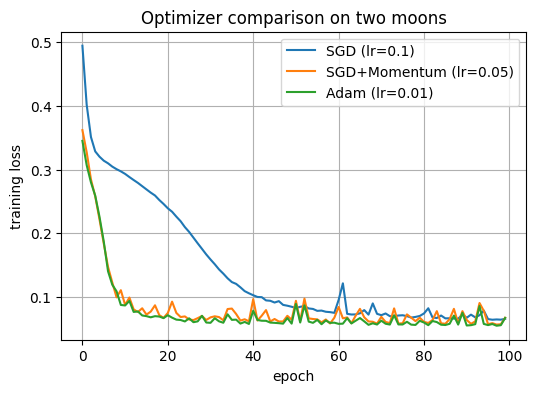

In [18]:
Xm, ym = make_moons(n_samples=1000, noise=0.2, random_state=42)
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(Xm, ym, test_size=0.25, random_state=42)
ym_tr, ym_te = ym_tr.reshape(-1, 1).astype(float), ym_te.reshape(-1, 1).astype(float)

nets = {}
for name, opt in {"SGD (lr=0.1)": SGD(lr=0.1),
                  "SGD+Momentum (lr=0.05)": SGD(lr=0.05, momentum=0.9),
                  "Adam (lr=0.01)": Adam(lr=0.01)}.items():
    net = NeuralNetwork([2, 16, 16, 1], "relu", "sigmoid", "bce", seed=1)
    net.fit(Xm_tr, ym_tr, epochs=100, batch_size=32, optimizer=opt,
            validation_data=(Xm_te, ym_te), verbose=0)
    nets[name] = net
    print(f"{name:24s} final train loss={net.history['loss'][-1]:.4f}  test accuracy={net.history['val_acc'][-1]:.4f}")

for name, net in nets.items():
    plt.plot(net.history["loss"], label=name)
plt.xlabel("epoch"); plt.ylabel("training loss"); plt.title("Optimizer comparison on two moons"); plt.legend(); plt.show()

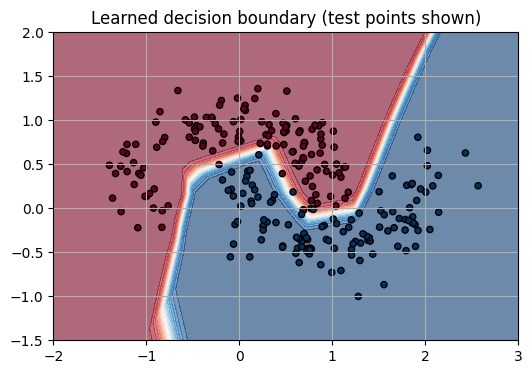

In [19]:
net = nets["Adam (lr=0.01)"]
gx, gy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grid = np.c_[gx.ravel(), gy.ravel()]
zz = net.predict_proba(grid).reshape(gx.shape)

plt.contourf(gx, gy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.scatter(Xm_te[:, 0], Xm_te[:, 1], c=ym_te.ravel(), cmap="RdBu", edgecolors="k", s=20)
plt.title("Learned decision boundary (test points shown)"); plt.show()

## 4.4 Multi-class classification: handwritten digits (8x8 images)

Output layer: 10 neurons with **softmax**, loss = **categorical cross-entropy**, labels are **one-hot encoded**.

Train: (1437, 64)  Test: (360, 64)


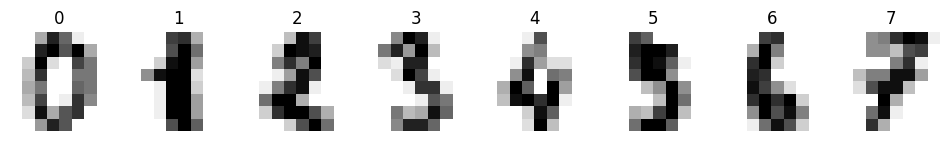

In [20]:
digits = load_digits()
Xd = digits.data / 16.0                         # scale pixel values to [0, 1]
yd = digits.target
Yd = np.eye(10)[yd]                             # one-hot encoding

Xd_tr, Xd_te, Yd_tr, Yd_te, yd_tr, yd_te = train_test_split(
    Xd, Yd, yd, test_size=0.2, random_state=42, stratify=yd)

print("Train:", Xd_tr.shape, " Test:", Xd_te.shape)

fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img, lab in zip(axes, digits.images[:8], digits.target[:8]):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab); ax.axis("off")
plt.show()

epoch    1  loss=1.2806  acc=0.7620  val_loss=1.2956  val_acc=0.7361
epoch   10  loss=0.0646  acc=0.9861  val_loss=0.1154  val_acc=0.9694
epoch   20  loss=0.0170  acc=0.9986  val_loss=0.0697  val_acc=0.9778
epoch   30  loss=0.0060  acc=1.0000  val_loss=0.0641  val_acc=0.9806
epoch   40  loss=0.0026  acc=1.0000  val_loss=0.0605  val_acc=0.9778
epoch   50  loss=0.0014  acc=1.0000  val_loss=0.0601  val_acc=0.9750
epoch   60  loss=0.0009  acc=1.0000  val_loss=0.0612  val_acc=0.9778

Test accuracy: 0.9778


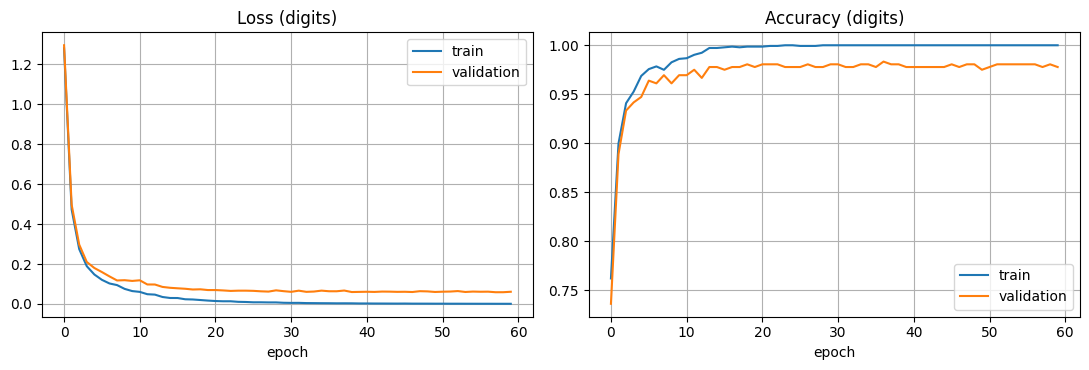

In [21]:
digit_net = NeuralNetwork([64, 64, 32, 10], hidden_activation="relu",
                          output_activation="softmax", loss="cce", seed=7)
digit_net.fit(Xd_tr, Yd_tr, epochs=60, batch_size=32, optimizer=Adam(lr=0.002),
              validation_data=(Xd_te, Yd_te), verbose=10)

test_acc = accuracy_score(yd_te, digit_net.predict(Xd_te))
print(f"\nTest accuracy: {test_acc:.4f}")
plot_history(digit_net, "(digits)")

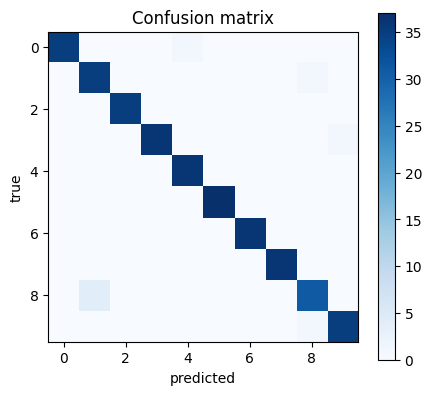

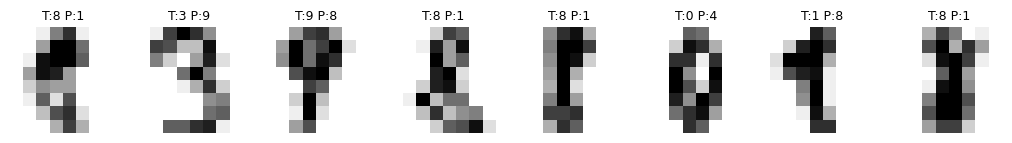

In [22]:
from sklearn.metrics import confusion_matrix
pred = digit_net.predict(Xd_te)
cm = confusion_matrix(yd_te, pred)

plt.figure(figsize=(5, 4.5))
plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix")
plt.grid(False); plt.show()

wrong = np.where(pred != yd_te)[0][:8]
if len(wrong):
    fig, axes = plt.subplots(1, len(wrong), figsize=(1.6 * len(wrong), 2))
    for ax, i in zip(np.atleast_1d(axes), wrong):
        ax.imshow(Xd_te[i].reshape(8, 8), cmap="gray_r")
        ax.set_title(f"T:{yd_te[i]} P:{pred[i]}", fontsize=9); ax.axis("off")
    plt.show()

## 4.5 Putting Part 1 and Part 4 together: save and reload the from-scratch model

Our network's learned state is just a dictionary of NumPy arrays plus a few settings, so `pickle` / `joblib` handle it easily.

In [23]:
digit_net.save("models/digit_net_scratch.joblib")
restored = NeuralNetwork.load("models/digit_net_scratch.joblib")

print("Original accuracy:", accuracy_score(yd_te, digit_net.predict(Xd_te)))
print("Restored accuracy:", accuracy_score(yd_te, restored.predict(Xd_te)))
print("Identical outputs:", np.allclose(digit_net.predict_proba(Xd_te), restored.predict_proba(Xd_te)))

# The same thing with plain pickle
with open("models/digit_net_scratch.pkl", "wb") as f:
    pickle.dump(digit_net, f)
with open("models/digit_net_scratch.pkl", "rb") as f:
    restored_pkl = pickle.load(f)
print("Pickle round-trip accuracy:", accuracy_score(yd_te, restored_pkl.predict(Xd_te)))

Original accuracy: 0.9777777777777777
Restored accuracy: 0.9777777777777777
Identical outputs: True
Pickle round-trip accuracy: 0.9777777777777777


## 4.6 Regression example (linear output + MSE)

To show the same class handles regression: learn $y = \sin(x)$ from noisy samples.

epoch    1  loss=0.0877  acc=nan
epoch  100  loss=0.0119  acc=nan
epoch  200  loss=0.0104  acc=nan
epoch  300  loss=0.0114  acc=nan


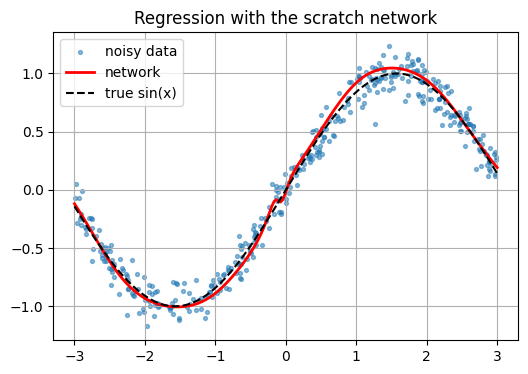

In [24]:
rng = np.random.default_rng(0)
Xr = rng.uniform(-3, 3, (400, 1))
Yr = np.sin(Xr) + rng.normal(0, 0.1, Xr.shape)

reg = NeuralNetwork([1, 32, 32, 1], "tanh", "linear", "mse", seed=5)
reg.fit(Xr, Yr, epochs=300, batch_size=32, optimizer=Adam(lr=0.01), verbose=100)

xs = np.linspace(-3, 3, 200).reshape(-1, 1)
plt.scatter(Xr, Yr, s=8, alpha=0.5, label="noisy data")
plt.plot(xs, reg.predict(xs), "r", lw=2, label="network")
plt.plot(xs, np.sin(xs), "k--", label="true sin(x)")
plt.legend(); plt.title("Regression with the scratch network"); plt.show()

---
# Summary

| Concept | Key takeaway |
|---|---|
| Model persistence | `pickle` (stdlib) and `joblib` (better for NumPy-heavy objects); save the full pipeline + metadata; never load untrusted files |
| Perceptron | linear classifier with a step activation; fails on XOR |
| Activations | add non-linearity; ReLU for hidden layers, sigmoid/softmax for outputs |
| Forward pass | `Z = A_prev @ W + b`, `A = f(Z)` layer by layer |
| Backward pass | chain rule from the loss back to each weight; verify with gradient checking |
| Loss | MSE for regression, BCE for binary, categorical CE for multi-class |
| Optimizers | SGD (+momentum) is simple; Adam adapts per-parameter steps and is a strong default |

